[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/data-engineering-from-scratch-to-advanced/blob/main/notebooks/topics/15_streaming.ipynb)

*Data Engineering from Scratch to Advanced · Notebook 15 of 21*

# Stream Processing

Processing data that never ends: event time vs processing time, tumbling, sliding and session windows, watermarks and late data, stateful processing, stream joins, checkpoints and exactly-once, with Spark and Flink in mind.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A stream never ends, so you draw windows on it, and a watermark decides when you've waited long enough.

**What interviewers really test here:** Event time, windows, watermarks, state and exactly-once.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Thinking in streams *(Basics)*
- [ ] 2. Event time and watermarks *(Core)*
- [ ] 3. State and joins *(Core)*
- [ ] 4. Failure, exactly-once and architecture *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Output modes in Structured Streaming

| Mode | Emits | Needs |
| --- | --- | --- |
| Append | final rows once a window closes | a watermark for aggregates |
| Update | rows that changed this trigger | a sink that can update |
| Complete | the whole result each time | memory for everything |

---
# Part 2: Lessons, step by step

## Lesson 1: Thinking in streams

*Level: Basics*

A batch job has an end. A stream doesn't, so "total sales today" has no obvious moment to finish. Stream processing answers this with **windows**, which cut an endless stream into finite pieces.



| Window | Shape | Use |
| --- | --- | --- |
| Tumbling | fixed, no overlap | counts per minute |
| Sliding | fixed, overlapping | a 10-minute average, updated every 5 |
| Session | ends after a gap | user visits |



```text
Tumbling (60s): [0───60)[60──120)[120─180)
Sliding (10s, every 5s): [0──10) [5──15) [10─20)
Session (gap 5): 1 2 ····· 10 11 12 ········ 30
```



**By hand.** Times 1, 2, 61, 62, 130 in 60-second tumbling windows: window start = t − t % 60, giving {0: 2, 60: 2, 120: 1}.



In a sliding window of size 10 every 5, an event at 12 belongs to the windows starting at 5 and 10. Times 1, 2, 10, 11, 12, 30 with a session gap of 5 make 3 sessions: 1–2, 10–12 and 30.



```python
counts = (events
    .withWatermark("ts", "10 minutes")
    .groupBy(F.window("ts", "5 minutes"), "page")
    .count())
query = counts.writeStream.outputMode("append").format("parquet") \
    .option("path", out).option("checkpointLocation", ckpt).start()
```



This Structured Streaming code needs a running source, so it's shown as text here. The practice questions model the same logic in plain Python.

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q8](#q8), [Q9](#q9), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 2: Event time and watermarks

*Level: Core*

**Events arrive late and out of order.** A click at 55 s might arrive at 62 s. Grouping by arrival time would put it in the wrong minute: for events (55, 62), (58, 59), (61, 65), event time gives {minute 0: 2, minute 1: 1}, while arrival time gives {minute 0: 1, minute 1: 2}.



So group by event time. But then when can you close a window? You can't wait forever. A **watermark** is the system's estimate of how far event time has got:



**watermark = largest event time seen − allowed lateness**



Times 10, 20, 15, 30 with lateness 5 give watermarks 5, 15, 15, 25. It never goes backward.



**What it controls:** a window closes when the watermark passes its end. Events for closed windows are dropped, and that window's state can be freed. Window [0, 60) with lateness 10 closes once an event at 70 arrives.



| Lateness setting | Result |
| --- | --- |
| Small | fast results, more dropped events |
| Large | complete results, slower, more state |



The chart shows the watermark trailing the maximum event time, and a late event falling behind it. **Choose lateness from measured delays**, and count what's dropped.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

late events dropped: 12 of 100


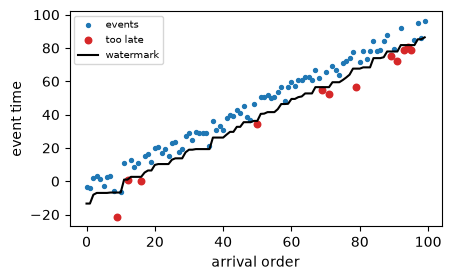

In [2]:
def watermark_chart():
    rng = np.random.default_rng(0)
    arrivals = np.arange(100)
    event_time = arrivals - rng.exponential(5, 100)
    top = np.maximum.accumulate(event_time)
    watermark = top - 10
    late = event_time < watermark
    print("late events dropped:", int(late.sum()), "of", len(late))
    fig, ax = plt.subplots(figsize=(4.8, 2.8))
    ax.scatter(arrivals, event_time, s=8, label="events")
    ax.scatter(arrivals[late], event_time[late], s=22, color="tab:red", label="too late")
    ax.plot(arrivals, watermark, color="black", label="watermark")
    ax.set_xlabel("arrival order")
    ax.set_ylabel("event time")
    ax.legend(fontsize=7)


watermark_chart()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q3](#q3), [Q10](#q10), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 3: State and joins

*Level: Core*

**Counting needs memory.** A running count per key is **state**, and with a stream that runs for years, state can grow until it crashes. Four keys seen forever is fine, but a billion isn't. A **TTL** or a watermark removes old state: of 3 keys seen, only 2 are still live after a 30-second TTL.



**State stores:** Flink and Spark can keep large state in RocksDB on local disk, and checkpoint it to object storage.



| Join | How | State |
| --- | --- | --- |
| Stream-static | look each event up in a table | none |
| Stream-stream | buffer both sides until a match can no longer arrive | grows with the time range |



**Stream-stream by hand.** Impressions and clicks, with a click valid within 30 s. The impression at 10 and click at 15 match. The click at 90 for an impression at 20 is too late. The click for ad 3 has no impression. Without a time limit, you'd need to buffer forever.



**Deduplication** also needs state, limited by a window. Ids older than the window are forgotten, so a very late repeat can get through. That's a deliberate trade-off.



**Approximate answers save huge amounts of state:**



| Sketch | Answers | Note |
| --- | --- | --- |
| HyperLogLog | how many distinct? | about 1–2% error in kilobytes |
| Count-Min | how often? | may overestimate, never under |
| Bloom filter | seen before? | "maybe" or "definitely not" |



Our single-counter HyperLogLog sketch estimates 2,048 for 1,000 distinct items, as one counter is very rough. Real HLL averages thousands of buckets.

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q12](#q12), [Q5](#q5), [Q18](#q18), [Q15](#q15), [Q19](#q19), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 4: Failure, exactly-once and architecture

*Level: Advanced*

**Checkpoints.** A job periodically saves its input offsets and state together. After a crash it restores both and replays. With a checkpoint every 4 events and a crash at 7, it restores 4 and replays 3, and still ends on the right total of 10.



**End-to-end exactly-once needs three things:** a replayable source, checkpointed state, and an idempotent or transactional sink. Replaying a record into an append sink gives 3 rows for 2 records, and an upsert sink gives 2.



**Spark vs Flink:**



|   | Spark Structured Streaming | Flink |
| --- | --- | --- |
| Model | micro-batches | record at a time |
| Latency | seconds | milliseconds possible |
| Strength | same API as batch | advanced state and event time |



**Micro-batch stability.** With a 10 s trigger and 2 s runtime, average latency is 7 s and the worst is 12 s. A 15 s runtime on a 10 s trigger means it falls further behind forever.



**Backpressure.** Arrivals of 5, 20, 5, 5 with capacity 10 give a queue of 0, 10, 5, 0. It recovers. If average input exceeds capacity, the queue never recovers.



| Architecture | Idea | Trade-off |
| --- | --- | --- |
| Lambda | separate batch and stream paths | accurate, but two code bases |
| Kappa | one stream path; replay to reprocess | simpler, needs long retention |

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q17](#q17), [Q6](#q6), [Q14](#q14), [Q7](#q7). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [3]:
from collections import defaultdict


<a id="q1"></a>
### Q1. Tumbling Windows

🟢 Warm-up · *Fixed buckets*

Count events by window of size w: window start = t − t % w. Return {start: count}, sorted.

**Examples**

- `times = [1, 2, 61, 62, 130], w = 60` → `{0: 2, 60: 2, 120: 1}`

In [ ]:
def tumbling(times, w):
    """
    Count events by window of size w: window start = t − t % w. Return {start:
    count}, sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(tumbling, [
    (([1, 2, 61, 62, 130], 60), {0: 2, 60: 2, 120: 1}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A dictionary in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Counter`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A dictionary in a loop.

```python
def tumbling(times, w):
    counts = {}
    for t in times:
        start = t - t % w
        counts[start] = counts.get(start, 0) + 1
    return dict(sorted(counts.items()))
```

**Cost:** O(n) time, O(w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Counter`.

```python
def tumbling(times, w):
    from collections import Counter
    return dict(sorted(Counter(t - t % w for t in times).items()))
```

**Cost:** O(n) time, O(w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A dictionary in a loop. That costs O(n) time and O(w) space."

"I can do better: `Counter`. That's O(n) time and O(w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/tumbling-windows)

<a id="q2"></a>
### Q2. Event Time vs Processing Time

🟢 Warm-up · *Which bucket?*

Events are (event\_time, arrival\_time). Return per-window counts by event time and by arrival time, for window w.

**Examples**

- `events = [(55, 62), (58, 59), (61, 65)], w = 60` → `({0: 2, 1: 1}, {0: 1, 1: 2})`

In [ ]:
def time_buckets(events, w):
    """
    Events are (event_time, arrival_time). Return per-window counts by event
    time and by arrival time, for window w.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(time_buckets, [
    (([(55, 62), (58, 59), (61, 65)], 60), ({0: 2, 1: 1}, {0: 1, 1: 2})),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two dictionaries.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A helper used twice.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Two dictionaries.

```python
def time_buckets(events, w):
    by_event, by_arrival = {}, {}
    for e, a in events:
        by_event[e // w] = by_event.get(e // w, 0) + 1
        by_arrival[a // w] = by_arrival.get(a // w, 0) + 1
    return (dict(sorted(by_event.items())), dict(sorted(by_arrival.items())))
```

**Cost:** O(n) time, O(w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A helper used twice.

```python
def time_buckets(events, w):
    from collections import Counter
    count = lambda i: dict(sorted(Counter(x[i] // w for x in events).items()))
    return (count(0), count(1))
```

**Cost:** O(n) time, O(w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two dictionaries. That costs O(n) time and O(w) space."

"I can do better: A helper used twice. That's O(n) time and O(w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/event-time-vs-processing-time)

<a id="q3"></a>
### Q3. Compute the Watermark

🟢 Warm-up · *How late is too late?*

Watermark = largest event time seen so far − lateness. Return the watermark after each event.

**Examples**

- `times = [10, 20, 15, 30], lateness = 5` → `[5, 15, 15, 25]`

In [ ]:
def watermarks(times, lateness):
    """
    Watermark = largest event time seen so far − lateness. Return the watermark
    after each event.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(watermarks, [
    (([10, 20, 15, 30], 5), [5, 15, 15, 25]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track a maximum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`itertools.accumulate(max)`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Track a maximum.

```python
def watermarks(times, lateness):
    out, top = [], times[0]
    for t in times:
        if t > top:
            top = t
        out.append(top - lateness)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `itertools.accumulate(max)`.

```python
def watermarks(times, lateness):
    import itertools
    return [m - lateness for m in itertools.accumulate(times, max)]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track a maximum. That costs O(n) time and O(n) space."

"I can do better: `itertools.accumulate(max)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/compute-the-watermark)

<a id="q4"></a>
### Q4. Running Count With State

🟢 Warm-up · *Stateful processing*

For a stream of keys, return the running count per key after each event.

**Examples**

- `keys = ['a', 'b', 'a']` → `[1, 1, 2]`

In [ ]:
def running_counts(keys):
    """
    For a stream of keys, return the running count per key after each event.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(running_counts, [
    ((['a', 'b', 'a'],), [1, 1, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A dictionary.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`defaultdict(int)`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A dictionary.

```python
def running_counts(keys):
    state, out = {}, []
    for k in keys:
        state[k] = state.get(k, 0) + 1
        out.append(state[k])
    return out
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `defaultdict(int)`.

```python
def running_counts(keys):
    state = defaultdict(int)
    out = []
    for k in keys:
        state[k] += 1
        out.append(state[k])
    return out
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A dictionary. That costs O(n) time and O(k) space."

"I can do better: `defaultdict(int)`. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/running-count-with-state)

<a id="q5"></a>
### Q5. Stream-Static Join

🟢 Warm-up · *Enrich events*

Join each event (id, user) with a user table to add a country, using 'unknown' if not found.

**Examples**

- `events = [(1, 'u1'), (2, 'u9')], users = {'u1': 'IN'}` → `[[1, 'u1', 'IN'], [2, 'u9', 'unknown']]`

In [ ]:
def enrich(events, users):
    """
    Join each event (id, user) with a user table to add a country, using
    'unknown' if not found.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(enrich, [
    (([(1, 'u1'), (2, 'u9')], {'u1': 'IN'}), [[1, 'u1', 'IN'], [2, 'u9', 'unknown']]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Search a list of pairs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dictionary lookup.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Search a list of pairs.

```python
def enrich(events, users):
    out = []
    for i, u in events:
        country = "unknown"
        for name in users:
            if name == u:
                country = users[name]
        out.append([i, u, country])
    return out
```

**Cost:** O(n·m) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dictionary lookup.

```python
def enrich(events, users):
    return [[i, u, users.get(u, "unknown")] for i, u in events]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Search a list of pairs. That costs O(n·m) time and O(n) space."

"I can do better: A dictionary lookup. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/stream-static-join)

<a id="q6"></a>
### Q6. Micro-Batch Latency

🟢 Warm-up · *Spark's model*

With trigger interval t seconds and batch run time r, return the average and worst latency: wait for the batch, plus processing. Stable only if r ≤ t.

**Examples**

- `t = 10, r = 2` → `(7.0, 12, True)`
- `t = 10, r = 15` → `(20.0, 25, False)`

In [ ]:
def micro_batch(t, r):
    """
    With trigger interval t seconds and batch run time r, return the average and
    worst latency: wait for the batch, plus processing. Stable only if r ≤ t.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(micro_batch, [
    ((10, 2), (7.0, 12, True)),
    ((10, 15), (20.0, 25, False)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compact.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Add up.

```python
def micro_batch(t, r):
    average = t / 2 + r
    worst = t + r
    stable = r <= t
    return (average, worst, stable)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Compact.

```python
def micro_batch(t, r):
    return (t / 2 + r, t + r, r <= t)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up. That costs O(1) time and O(1) space."

"I can do better: Compact. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/micro-batch-latency)

<a id="q7"></a>
### Q7. Lambda or Kappa?

🟢 Warm-up · *Two architectures*

Lambda runs batch and streaming code paths; Kappa uses only a stream with replay. Return the number of code paths and, for a change, the deployments needed.

**Examples**

- `name = 'lambda'` → `(2, 2)`
- `name = 'kappa'` → `(1, 1)`

In [ ]:
def architecture(name):
    """
    Lambda runs batch and streaming code paths; Kappa uses only a stream with
    replay. Return the number of code paths and, for a change, the deployments
    needed.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(architecture, [
    (('lambda',), (2, 2)),
    (('kappa',), (1, 1)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dictionary.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs.

```python
def architecture(name):
    if name == "lambda":
        return (2, 2)
    return (1, 1)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dictionary.

```python
def architecture(name):
    return {"lambda": (2, 2), "kappa": (1, 1)}[name]
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs. That costs O(1) time and O(1) space."

"I can do better: A dictionary. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/lambda-or-kappa)

<a id="q8"></a>
### Q8. Sliding Windows

🟡 Interview standard · *One event, many windows*

With size s and slide d, an event belongs to each window [k·d, k·d + s) containing it. Return {start: count}, sorted.

**Examples**

- `times = [5, 12], s = 10, d = 5` → `{0: 1, 5: 2, 10: 1}`

In [ ]:
def sliding(times, s, d):
    """
    With size s and slide d, an event belongs to each window [k·d, k·d + s)
    containing it. Return {start: count}, sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sliding, [
    (([5, 12], 10, 5), {0: 1, 5: 2, 10: 1}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Check each candidate window.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compute the starting points directly.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Check each candidate window.

```python
def sliding(times, s, d):
    last = max(times)
    counts = {}
    k = 0
    while k * d <= last:
        n = sum(1 for t in times if k * d <= t < k * d + s)
        if n:
            counts[k * d] = n
        k += 1
    return counts
```

**Cost:** O(n·w) time, O(w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Compute the starting points directly.

```python
def sliding(times, s, d):
    counts = defaultdict(int)
    for t in times:
        start = t - t % d
        while start > t - s and start >= 0:
            counts[start] += 1
            start -= d
    return dict(sorted(counts.items()))
```

**Cost:** O(n·s/d) time, O(w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Check each candidate window. That costs O(n·w) time and O(w) space."

"I can do better: Compute the starting points directly. That's O(n·s/d) time and O(w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/sliding-windows)

<a id="q9"></a>
### Q9. Session Windows

🟡 Interview standard · *Activity bursts*

Sessions end after a gap larger than g. Given sorted times, return [start, end, count] per session.

**Examples**

- `times = [1, 2, 10, 11, 12, 30], g = 5` → `[[1, 2, 2], [10, 12, 3], [30, 30, 1]]`

In [ ]:
def sessions(times, g):
    """
    Sessions end after a gap larger than g. Given sorted times, return [start,
    end, count] per session.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sessions, [
    (([1, 2, 10, 11, 12, 30], 5), [[1, 2, 2], [10, 12, 3], [30, 30, 1]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop tracking the current session.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same loop, with lists.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop tracking the current session.

```python
def sessions(times, g):
    out = []
    for t in times:
        if out and t - out[-1][1] <= g:
            out[-1][1] = t
            out[-1][2] += 1
        else:
            out.append([t, t, 1])
    return out
```

**Cost:** O(n) time, O(s) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same loop, with lists.

```python
def sessions(times, g):
    import itertools
    breaks = [0] + [t - p > g for p, t in zip(times, times[1:])]
    ids = itertools.accumulate(map(int, breaks))
    groups = itertools.groupby(zip(ids, times), key=lambda x: x[0])
    out = []
    for _, g_ in groups:
        ts = [t for _, t in g_]
        out.append([ts[0], ts[-1], len(ts)])
    return out
```

**Cost:** O(n) time, O(s) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop tracking the current session. That costs O(n) time and O(s) space."

"I can do better: Same loop, with lists. That's O(n) time and O(s) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/session-windows)

<a id="q10"></a>
### Q10. Drop Late Events

🟡 Interview standard · *Watermarks in action*

Process events in arrival order. An event whose window has closed (window end ≤ current watermark) is dropped. Return (counts per window start, dropped count) for window w and lateness l.

**Examples**

- `times = [10, 70, 15, 130, 65], w = 60, l = 5` → `({0: 1, 60: 1, 120: 1}, 2)`

In [ ]:
def late_filter(times, w, l):
    """
    Process events in arrival order. An event whose window has closed (window
    end ≤ current watermark) is dropped. Return (counts per window start,
    dropped count) for window w and lateness l.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(late_filter, [
    (([10, 70, 15, 130, 65], 60, 5), ({0: 1, 60: 1, 120: 1}, 2)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track watermark in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same, with defaultdict.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Track watermark in a loop.

```python
def late_filter(times, w, l):
    top, counts, dropped = -10**9, {}, 0
    for t in times:
        start = t - t % w
        if start + w <= top - l:
            dropped += 1
            continue
        counts[start] = counts.get(start, 0) + 1
        top = max(top, t)
    return (dict(sorted(counts.items())), dropped)
```

**Cost:** O(n) time, O(w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same, with defaultdict.

```python
def late_filter(times, w, l):
    counts, dropped, wm = defaultdict(int), 0, float("-inf")
    for t in times:
        start = t - t % w
        if start + w <= wm:
            dropped += 1
        else:
            counts[start] += 1
            wm = max(wm, t - l)
    return (dict(sorted(counts.items())), dropped)
```

**Cost:** O(n) time, O(w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track watermark in a loop. That costs O(n) time and O(w) space."

"I can do better: Same, with defaultdict. That's O(n) time and O(w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/drop-late-events)

<a id="q11"></a>
### Q11. When Does a Window Fire?

🟡 Interview standard · *Output mode: append*

A window [s, s + w) emits when the watermark reaches s + w. Given arrival-ordered event times and lateness, return the event index at which window s closes, or None.

**Examples**

- `times = [10, 70, 200], s = 0, w = 60, lateness = 10` → `1`
- `times = [10, 20], s = 0, w = 60, lateness = 10` → `None`

In [ ]:
def window_fires(times, s, w, lateness):
    """
    A window [s, s + w) emits when the watermark reaches s + w. Given arrival-
    ordered event times and lateness, return the event index at which window s
    closes, or None.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(window_fires, [
    (([10, 70, 200], 0, 60, 10), 1),
    (([10, 20], 0, 60, 10), None),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track the maximum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`next` over accumulated maximums.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Track the maximum.

```python
def window_fires(times, s, w, lateness):
    top = None
    for i, t in enumerate(times):
        top = t if top is None or t > top else top
        if top - lateness >= s + w:
            return i
    return None
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `next` over accumulated maximums.

```python
def window_fires(times, s, w, lateness):
    import itertools
    return next((i for i, m in enumerate(itertools.accumulate(times, max)) if m - lateness >= s + w), None)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track the maximum. That costs O(n) time and O(1) space."

"I can do better: `next` over accumulated maximums. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/when-does-a-window-fire)

<a id="q12"></a>
### Q12. State Growth

🟡 Interview standard · *State can blow up*

Without eviction, state grows with distinct keys. With a TTL, keys expire. Given (key, time) events in order and ttl, return (keys kept forever, keys in state at the end).

**Examples**

- `events = [('a', 1), ('b', 2), ('c', 50), ('a', 60)], ttl = 30` → `(3, 2)`

In [ ]:
def state_size(events, ttl):
    """
    Without eviction, state grows with distinct keys. With a TTL, keys expire.
    Given (key, time) events in order and ttl, return (keys kept forever, keys
    in state at the end).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(state_size, [
    (([('a', 1), ('b', 2), ('c', 50), ('a', 60)], 30), (3, 2)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A dictionary, then filter.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same, compactly.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A dictionary, then filter.

```python
def state_size(events, ttl):
    last = {}
    now = 0
    for k, t in events:
        last[k] = t
        now = t
    live = 0
    for k in last:
        if now - last[k] <= ttl:
            live += 1
    return (len(last), live)
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same, compactly.

```python
def state_size(events, ttl):
    last = dict(events)
    now = events[-1][1]
    return (len(last), sum(now - t <= ttl for t in last.values()))
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A dictionary, then filter. That costs O(n) time and O(k) space."

"I can do better: Same, compactly. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/state-growth)

<a id="q13"></a>
### Q13. Checkpoint and Replay

🟡 Interview standard · *Fault tolerance*

A stream job checkpoints state and offset every k events. A crash happens after event c. Return (restored count from the checkpoint, events replayed, final total, all events counted once).

**Examples**

- `n = 10, k = 4, c = 7` → `(4, 3, 10)`

In [ ]:
def stream_recover(n, k, c):
    """
    A stream job checkpoints state and offset every k events. A crash happens
    after event c. Return (restored count from the checkpoint, events replayed,
    final total, all events counted once).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(stream_recover, [
    ((10, 4, 7), (4, 3, 10)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Simulate it.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Arithmetic.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Simulate it.

```python
def stream_recover(n, k, c):
    count = saved = 0
    for i in range(1, c + 1):
        count += 1
        if i % k == 0:
            saved = count
    replayed = c - saved
    total = saved
    for _ in range(saved, n):
        total += 1
    return (saved, replayed, total)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Arithmetic.

```python
def stream_recover(n, k, c):
    saved = c // k * k
    return (saved, c - saved, n)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Simulate it. That costs O(n) time and O(1) space."

"I can do better: Arithmetic. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/checkpoint-and-replay)

<a id="q14"></a>
### Q14. Backpressure

🟡 Interview standard · *When input outruns output*

Given per-second input counts and a capacity, return the queue length after each second.

**Examples**

- `arrivals = [5, 20, 5, 5], capacity = 10` → `[0, 10, 5, 0]`

In [ ]:
def backlog(arrivals, capacity):
    """
    Given per-second input counts and a capacity, return the queue length after
    each second.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(backlog, [
    (([5, 20, 5, 5], 10), [0, 10, 5, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A running queue.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`itertools.accumulate` with a function.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A running queue.

```python
def backlog(arrivals, capacity):
    queue, out = 0, []
    for a in arrivals:
        queue = max(0, queue + a - capacity)
        out.append(queue)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `itertools.accumulate` with a function.

```python
def backlog(arrivals, capacity):
    import itertools
    return list(itertools.accumulate(arrivals, lambda q, a: max(0, q + a - capacity), initial=0))[1:]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A running queue. That costs O(n) time and O(n) space."

"I can do better: `itertools.accumulate` with a function. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/backpressure)

<a id="q15"></a>
### Q15. Deduplicate With a Watermark

🟡 Interview standard · *Bound the state*

Drop repeated ids within the window. Keep state only for ids newer than watermark = max time − w. Return (kept ids, final state size).

**Examples**

- `events = [('a', 1), ('a', 2), ('b', 50), ('a', 60)], w = 10` → `(['a', 'b', 'a'], 2)`

In [ ]:
def watermark_dedupe(events, w):
    """
    Drop repeated ids within the window. Keep state only for ids newer than
    watermark = max time − w. Return (kept ids, final state size).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(watermark_dedupe, [
    (([('a', 1), ('a', 2), ('b', 50), ('a', 60)], 10), (['a', 'b', 'a'], 2)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A dictionary with eviction in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same with a comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A dictionary with eviction in a loop.

```python
def watermark_dedupe(events, w):
    state, kept, top = {}, [], 0
    for i, t in events:
        top = max(top, t)
        if i not in state:
            kept.append(i)
        state[i] = t
        for k in list(state):
            if state[k] < top - w:
                del state[k]
    return (kept, len(state))
```

**Cost:** O(n·k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same with a comprehension.

```python
def watermark_dedupe(events, w):
    state, kept, top = {}, [], 0
    for i, t in events:
        top = max(top, t)
        if i not in state:
            kept.append(i)
        state[i] = t
        state = {k: v for k, v in state.items() if v >= top - w}
    return (kept, len(state))
```

**Cost:** O(n·k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A dictionary with eviction in a loop. That costs O(n·k) time and O(k) space."

"I can do better: Same with a comprehension. That's O(n·k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/deduplicate-with-a-watermark)

<a id="q16"></a>
### Q16. Top K per Window

🟡 Interview standard · *Trending items*

Given (time, item) events and window w, return the top item per window (ties alphabetical), sorted by window start.

**Examples**

- `events = [(1, 'a'), (2, 'b'), (3, 'b'), (61, 'c')], w = 60` → `[[0, 'b'], [60, 'c']]`

In [ ]:
def top_per_window(events, w):
    """
    Given (time, item) events and window w, return the top item per window (ties
    alphabetical), sorted by window start.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(top_per_window, [
    (([(1, 'a'), (2, 'b'), (3, 'b'), (61, 'c')], 60), [[0, 'b'], [60, 'c']]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested dictionaries.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`defaultdict(Counter)`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Nested dictionaries.

```python
def top_per_window(events, w):
    windows = {}
    for t, item in events:
        start = t - t % w
        windows.setdefault(start, {})
        windows[start][item] = windows[start].get(item, 0) + 1
    out = []
    for s in sorted(windows):
        best = sorted(windows[s].items(), key=lambda kv: (-kv[1], kv[0]))[0][0]
        out.append([s, best])
    return out
```

**Cost:** O(n log k) time, O(w·k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `defaultdict(Counter)`.

```python
def top_per_window(events, w):
    from collections import Counter
    wins = defaultdict(Counter)
    for t, item in events:
        wins[t - t % w][item] += 1
    return [[s, min(c, key=lambda i: (-c[i], i))] for s, c in sorted(wins.items())]
```

**Cost:** O(n log k) time, O(w·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested dictionaries. That costs O(n log k) time and O(w·k) space."

"I can do better: `defaultdict(Counter)`. That's O(n log k) time and O(w·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/top-k-per-window)

<a id="q17"></a>
### Q17. Replays Need an Idempotent Sink

🟡 Interview standard · *Exactly-once in effect*

A stream replays after a crash, so a record can arrive twice. Return (rows in an append sink, rows in an upsert sink keyed by id).

**Examples**

- `records = [(1, 'a'), (2, 'b'), (1, 'a')]` → `(3, 2)`

In [ ]:
def sink_rows(records):
    """
    A stream replays after a crash, so a record can arrive twice. Return (rows
    in an append sink, rows in an upsert sink keyed by id).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sink_rows, [
    (([(1, 'a'), (2, 'b'), (1, 'a')],), (3, 2)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Simulate both sinks.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A list length and a dictionary.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Simulate both sinks.

```python
def sink_rows(records):
    append, upsert = [], {}
    for key, value in records:
        append.append((key, value))
        upsert[key] = value
    return (len(append), len(upsert))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A list length and a dictionary.

```python
def sink_rows(records):
    return (len(records), len(dict(records)))
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Simulate both sinks. That costs O(n) time and O(n) space."

"I can do better: A list length and a dictionary. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/replays-need-an-idempotent-sink)

<a id="q18"></a>
### Q18. Stream-Stream Join

🔴 Stretch · *Both sides arrive over time*

Join clicks and impressions by ad id if click time is within w seconds after the impression. Events arrive together, in time order, as (kind, id, time). Return matched [id, impression\_time, click\_time].

**Examples**

- `events = [('imp', 1, 10), ('click', 1, 15), ('imp', 2, 20), ('click', 2, 90), ('click', 3, 95)], w = 30` → `[[1, 10, 15]]`

In [ ]:
def stream_join(events, w):
    """
    Join clicks and impressions by ad id if click time is within w seconds after
    the impression. Events arrive together, in time order, as (kind, id, time).
    Return matched [id, impression_time, click_time].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(stream_join, [
    (([('imp', 1, 10), ('click', 1, 15), ('imp', 2, 20), ('click', 2, 90), ('click', 3, 95)], 30), [[1, 10, 15]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan all previous impressions for each click.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Buffer impressions in a dictionary, dropping old ones, which is what stream state does.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Scan all previous impressions for each click.

```python
def stream_join(events, w):
    seen, out = [], []
    for kind, i, t in events:
        if kind == "imp":
            seen.append((i, t))
        else:
            for sid, st in seen:
                if sid == i and 0 <= t - st <= w:
                    out.append([i, st, t])
    return out
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Buffer impressions in a dictionary, dropping old ones, which is what stream state does.

```python
def stream_join(events, w):
    buffer, out = {}, []
    for kind, i, t in events:
        if kind == "imp":
            buffer[i] = t
        elif i in buffer:
            if t - buffer[i] <= w:
                out.append([i, buffer[i], t])
            else:
                del buffer[i]
    return out
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan all previous impressions for each click. That costs O(n²) time and O(n) space."

"I can do better: Buffer impressions in a dictionary, dropping old ones, which is what stream state does. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/stream-stream-join)

<a id="q19"></a>
### Q19. Approximate Distinct Counts

🔴 Stretch · *HyperLogLog's idea*

Hash each item with md5. Keep the maximum number of leading zero bits seen. Estimate distinct ≈ 2^max. Compare with the truth on a small set, returning (estimate, truth). This shows the idea; real HLL averages many buckets.

**Examples**

- `items = ['u0', 'u1', 'u2', 'u3', 'u4', 'u5', 'u6', 'u7', 'u8', 'u9', 'u10', 'u11', 'u12', 'u13', 'u14', 'u15', 'u16', 'u17', 'u18', 'u19', 'u20', 'u21', 'u22', 'u23', 'u24', 'u25', 'u26', 'u27', 'u28', 'u29', 'u30', 'u31', 'u32', 'u33', 'u34', 'u35', 'u36', 'u37', 'u38', 'u39', 'u40', 'u41', 'u42', 'u43', 'u44', 'u45', 'u46', 'u47', 'u48', 'u49', 'u50', 'u51', 'u52', 'u53', 'u54', 'u55', 'u56', 'u57', 'u58', 'u59', 'u60', 'u61', 'u62', 'u63', 'u64', 'u65', 'u66', 'u67', 'u68', 'u69', 'u70', 'u71', 'u72', 'u73', 'u74', 'u75', 'u76', 'u77', 'u78', 'u79', 'u80', 'u81', 'u82', 'u83', 'u84', 'u85', 'u86', 'u87', 'u88', 'u89', 'u90', 'u91', 'u92', 'u93', 'u94', 'u95', 'u96', 'u97', 'u98', 'u99', 'u100', 'u101', 'u102', 'u103', 'u104', 'u105', 'u106', 'u107', 'u108', 'u109', 'u110', 'u111', 'u112', 'u113', 'u114', 'u115', 'u116', 'u117', 'u118', 'u119', 'u120', 'u121', 'u122', 'u123', 'u124', 'u125', 'u126', 'u127', 'u128', 'u129', 'u130', 'u131', 'u132', 'u133', 'u134', 'u135', 'u136', 'u137', 'u138', 'u139', 'u140', 'u141', 'u142', 'u143', 'u144', 'u145', 'u146', 'u147', 'u148', 'u149', 'u150', 'u151', 'u152', 'u153', 'u154', 'u155', 'u156', 'u157', 'u158', 'u159', 'u160', 'u161', 'u162', 'u163', 'u164', 'u165', 'u166', 'u167', 'u168', 'u169', 'u170', 'u171', 'u172', 'u173', 'u174', 'u175', 'u176', 'u177', 'u178', 'u179', 'u180', 'u181', 'u182', 'u183', 'u184', 'u185', 'u186', 'u187', 'u188', 'u189', 'u190', 'u191', 'u192', 'u193', 'u194', 'u195', 'u196', 'u197', 'u198', 'u199', 'u200', 'u201', 'u202', 'u203', 'u204', 'u205', 'u206', 'u207', 'u208', 'u209', 'u210', 'u211', 'u212', 'u213', 'u214', 'u215', 'u216', 'u217', 'u218', 'u219', 'u220', 'u221', 'u222', 'u223', 'u224', 'u225', 'u226', 'u227', 'u228', 'u229', 'u230', 'u231', 'u232', 'u233', 'u234', 'u235', 'u236', 'u237', 'u238', 'u239', 'u240', 'u241', 'u242', 'u243', 'u244', 'u245', 'u246', 'u247', 'u248', 'u249', 'u250', 'u251', 'u252', 'u253', 'u254', 'u255', 'u256', 'u257', 'u258', 'u259', 'u260', 'u261', 'u262', 'u263', 'u264', 'u265', 'u266', 'u267', 'u268', 'u269', 'u270', 'u271', 'u272', 'u273', 'u274', 'u275', 'u276', 'u277', 'u278', 'u279', 'u280', 'u281', 'u282', 'u283', 'u284', 'u285', 'u286', 'u287', 'u288', 'u289', 'u290', 'u291', 'u292', 'u293', 'u294', 'u295', 'u296', 'u297', 'u298', 'u299', 'u300', 'u301', 'u302', 'u303', 'u304', 'u305', 'u306', 'u307', 'u308', 'u309', 'u310', 'u311', 'u312', 'u313', 'u314', 'u315', 'u316', 'u317', 'u318', 'u319', 'u320', 'u321', 'u322', 'u323', 'u324', 'u325', 'u326', 'u327', 'u328', 'u329', 'u330', 'u331', 'u332', 'u333', 'u334', 'u335', 'u336', 'u337', 'u338', 'u339', 'u340', 'u341', 'u342', 'u343', 'u344', 'u345', 'u346', 'u347', 'u348', 'u349', 'u350', 'u351', 'u352', 'u353', 'u354', 'u355', 'u356', 'u357', 'u358', 'u359', 'u360', 'u361', 'u362', 'u363', 'u364', 'u365', 'u366', 'u367', 'u368', 'u369', 'u370', 'u371', 'u372', 'u373', 'u374', 'u375', 'u376', 'u377', 'u378', 'u379', 'u380', 'u381', 'u382', 'u383', 'u384', 'u385', 'u386', 'u387', 'u388', 'u389', 'u390', 'u391', 'u392', 'u393', 'u394', 'u395', 'u396', 'u397', 'u398', 'u399', 'u400', 'u401', 'u402', 'u403', 'u404', 'u405', 'u406', 'u407', 'u408', 'u409', 'u410', 'u411', 'u412', 'u413', 'u414', 'u415', 'u416', 'u417', 'u418', 'u419', 'u420', 'u421', 'u422', 'u423', 'u424', 'u425', 'u426', 'u427', 'u428', 'u429', 'u430', 'u431', 'u432', 'u433', 'u434', 'u435', 'u436', 'u437', 'u438', 'u439', 'u440', 'u441', 'u442', 'u443', 'u444', 'u445', 'u446', 'u447', 'u448', 'u449', 'u450', 'u451', 'u452', 'u453', 'u454', 'u455', 'u456', 'u457', 'u458', 'u459', 'u460', 'u461', 'u462', 'u463', 'u464', 'u465', 'u466', 'u467', 'u468', 'u469', 'u470', 'u471', 'u472', 'u473', 'u474', 'u475', 'u476', 'u477', 'u478', 'u479', 'u480', 'u481', 'u482', 'u483', 'u484', 'u485', 'u486', 'u487', 'u488', 'u489', 'u490', 'u491', 'u492', 'u493', 'u494', 'u495', 'u496', 'u497', 'u498', 'u499', 'u500', 'u501', 'u502', 'u503', 'u504', 'u505', 'u506', 'u507', 'u508', 'u509', 'u510', 'u511', 'u512', 'u513', 'u514', 'u515', 'u516', 'u517', 'u518', 'u519', 'u520', 'u521', 'u522', 'u523', 'u524', 'u525', 'u526', 'u527', 'u528', 'u529', 'u530', 'u531', 'u532', 'u533', 'u534', 'u535', 'u536', 'u537', 'u538', 'u539', 'u540', 'u541', 'u542', 'u543', 'u544', 'u545', 'u546', 'u547', 'u548', 'u549', 'u550', 'u551', 'u552', 'u553', 'u554', 'u555', 'u556', 'u557', 'u558', 'u559', 'u560', 'u561', 'u562', 'u563', 'u564', 'u565', 'u566', 'u567', 'u568', 'u569', 'u570', 'u571', 'u572', 'u573', 'u574', 'u575', 'u576', 'u577', 'u578', 'u579', 'u580', 'u581', 'u582', 'u583', 'u584', 'u585', 'u586', 'u587', 'u588', 'u589', 'u590', 'u591', 'u592', 'u593', 'u594', 'u595', 'u596', 'u597', 'u598', 'u599', 'u600', 'u601', 'u602', 'u603', 'u604', 'u605', 'u606', 'u607', 'u608', 'u609', 'u610', 'u611', 'u612', 'u613', 'u614', 'u615', 'u616', 'u617', 'u618', 'u619', 'u620', 'u621', 'u622', 'u623', 'u624', 'u625', 'u626', 'u627', 'u628', 'u629', 'u630', 'u631', 'u632', 'u633', 'u634', 'u635', 'u636', 'u637', 'u638', 'u639', 'u640', 'u641', 'u642', 'u643', 'u644', 'u645', 'u646', 'u647', 'u648', 'u649', 'u650', 'u651', 'u652', 'u653', 'u654', 'u655', 'u656', 'u657', 'u658', 'u659', 'u660', 'u661', 'u662', 'u663', 'u664', 'u665', 'u666', 'u667', 'u668', 'u669', 'u670', 'u671', 'u672', 'u673', 'u674', 'u675', 'u676', 'u677', 'u678', 'u679', 'u680', 'u681', 'u682', 'u683', 'u684', 'u685', 'u686', 'u687', 'u688', 'u689', 'u690', 'u691', 'u692', 'u693', 'u694', 'u695', 'u696', 'u697', 'u698', 'u699', 'u700', 'u701', 'u702', 'u703', 'u704', 'u705', 'u706', 'u707', 'u708', 'u709', 'u710', 'u711', 'u712', 'u713', 'u714', 'u715', 'u716', 'u717', 'u718', 'u719', 'u720', 'u721', 'u722', 'u723', 'u724', 'u725', 'u726', 'u727', 'u728', 'u729', 'u730', 'u731', 'u732', 'u733', 'u734', 'u735', 'u736', 'u737', 'u738', 'u739', 'u740', 'u741', 'u742', 'u743', 'u744', 'u745', 'u746', 'u747', 'u748', 'u749', 'u750', 'u751', 'u752', 'u753', 'u754', 'u755', 'u756', 'u757', 'u758', 'u759', 'u760', 'u761', 'u762', 'u763', 'u764', 'u765', 'u766', 'u767', 'u768', 'u769', 'u770', 'u771', 'u772', 'u773', 'u774', 'u775', 'u776', 'u777', 'u778', 'u779', 'u780', 'u781', 'u782', 'u783', 'u784', 'u785', 'u786', 'u787', 'u788', 'u789', 'u790', 'u791', 'u792', 'u793', 'u794', 'u795', 'u796', 'u797', 'u798', 'u799', 'u800', 'u801', 'u802', 'u803', 'u804', 'u805', 'u806', 'u807', 'u808', 'u809', 'u810', 'u811', 'u812', 'u813', 'u814', 'u815', 'u816', 'u817', 'u818', 'u819', 'u820', 'u821', 'u822', 'u823', 'u824', 'u825', 'u826', 'u827', 'u828', 'u829', 'u830', 'u831', 'u832', 'u833', 'u834', 'u835', 'u836', 'u837', 'u838', 'u839', 'u840', 'u841', 'u842', 'u843', 'u844', 'u845', 'u846', 'u847', 'u848', 'u849', 'u850', 'u851', 'u852', 'u853', 'u854', 'u855', 'u856', 'u857', 'u858', 'u859', 'u860', 'u861', 'u862', 'u863', 'u864', 'u865', 'u866', 'u867', 'u868', 'u869', 'u870', 'u871', 'u872', 'u873', 'u874', 'u875', 'u876', 'u877', 'u878', 'u879', 'u880', 'u881', 'u882', 'u883', 'u884', 'u885', 'u886', 'u887', 'u888', 'u889', 'u890', 'u891', 'u892', 'u893', 'u894', 'u895', 'u896', 'u897', 'u898', 'u899', 'u900', 'u901', 'u902', 'u903', 'u904', 'u905', 'u906', 'u907', 'u908', 'u909', 'u910', 'u911', 'u912', 'u913', 'u914', 'u915', 'u916', 'u917', 'u918', 'u919', 'u920', 'u921', 'u922', 'u923', 'u924', 'u925', 'u926', 'u927', 'u928', 'u929', 'u930', 'u931', 'u932', 'u933', 'u934', 'u935', 'u936', 'u937', 'u938', 'u939', 'u940', 'u941', 'u942', 'u943', 'u944', 'u945', 'u946', 'u947', 'u948', 'u949', 'u950', 'u951', 'u952', 'u953', 'u954', 'u955', 'u956', 'u957', 'u958', 'u959', 'u960', 'u961', 'u962', 'u963', 'u964', 'u965', 'u966', 'u967', 'u968', 'u969', 'u970', 'u971', 'u972', 'u973', 'u974', 'u975', 'u976', 'u977', 'u978', 'u979', 'u980', 'u981', 'u982', 'u983', 'u984', 'u985', 'u986', 'u987', 'u988', 'u989', 'u990', 'u991', 'u992', 'u993', 'u994', 'u995', 'u996', 'u997', 'u998', 'u999']` → `(2048, 1000)`

In [ ]:
def hll_idea(items):
    """
    Hash each item with md5. Keep the maximum number of leading zero bits seen.
    Estimate distinct ≈ 2^max. Compare with the truth on a small set, returning
    (estimate, truth). This shows the idea; real HLL averages many buckets.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(hll_idea, [
    ((['u0', 'u1', 'u2', 'u3', 'u4', 'u5', 'u6', 'u7', 'u8', 'u9', 'u10', 'u11', 'u12', 'u13', 'u14', 'u15', 'u16', 'u17', 'u18', 'u19', 'u20', 'u21', 'u22', 'u23', 'u24', 'u25', 'u26', 'u27', 'u28', 'u29', 'u30', 'u31', 'u32', 'u33', 'u34', 'u35', 'u36', 'u37', 'u38', 'u39', 'u40', 'u41', 'u42', 'u43', 'u44', 'u45', 'u46', 'u47', 'u48', 'u49', 'u50', 'u51', 'u52', 'u53', 'u54', 'u55', 'u56', 'u57', 'u58', 'u59', 'u60', 'u61', 'u62', 'u63', 'u64', 'u65', 'u66', 'u67', 'u68', 'u69', 'u70', 'u71', 'u72', 'u73', 'u74', 'u75', 'u76', 'u77', 'u78', 'u79', 'u80', 'u81', 'u82', 'u83', 'u84', 'u85', 'u86', 'u87', 'u88', 'u89', 'u90', 'u91', 'u92', 'u93', 'u94', 'u95', 'u96', 'u97', 'u98', 'u99', 'u100', 'u101', 'u102', 'u103', 'u104', 'u105', 'u106', 'u107', 'u108', 'u109', 'u110', 'u111', 'u112', 'u113', 'u114', 'u115', 'u116', 'u117', 'u118', 'u119', 'u120', 'u121', 'u122', 'u123', 'u124', 'u125', 'u126', 'u127', 'u128', 'u129', 'u130', 'u131', 'u132', 'u133', 'u134', 'u135', 'u136', 'u137', 'u138', 'u139', 'u140', 'u141', 'u142', 'u143', 'u144', 'u145', 'u146', 'u147', 'u148', 'u149', 'u150', 'u151', 'u152', 'u153', 'u154', 'u155', 'u156', 'u157', 'u158', 'u159', 'u160', 'u161', 'u162', 'u163', 'u164', 'u165', 'u166', 'u167', 'u168', 'u169', 'u170', 'u171', 'u172', 'u173', 'u174', 'u175', 'u176', 'u177', 'u178', 'u179', 'u180', 'u181', 'u182', 'u183', 'u184', 'u185', 'u186', 'u187', 'u188', 'u189', 'u190', 'u191', 'u192', 'u193', 'u194', 'u195', 'u196', 'u197', 'u198', 'u199', 'u200', 'u201', 'u202', 'u203', 'u204', 'u205', 'u206', 'u207', 'u208', 'u209', 'u210', 'u211', 'u212', 'u213', 'u214', 'u215', 'u216', 'u217', 'u218', 'u219', 'u220', 'u221', 'u222', 'u223', 'u224', 'u225', 'u226', 'u227', 'u228', 'u229', 'u230', 'u231', 'u232', 'u233', 'u234', 'u235', 'u236', 'u237', 'u238', 'u239', 'u240', 'u241', 'u242', 'u243', 'u244', 'u245', 'u246', 'u247', 'u248', 'u249', 'u250', 'u251', 'u252', 'u253', 'u254', 'u255', 'u256', 'u257', 'u258', 'u259', 'u260', 'u261', 'u262', 'u263', 'u264', 'u265', 'u266', 'u267', 'u268', 'u269', 'u270', 'u271', 'u272', 'u273', 'u274', 'u275', 'u276', 'u277', 'u278', 'u279', 'u280', 'u281', 'u282', 'u283', 'u284', 'u285', 'u286', 'u287', 'u288', 'u289', 'u290', 'u291', 'u292', 'u293', 'u294', 'u295', 'u296', 'u297', 'u298', 'u299', 'u300', 'u301', 'u302', 'u303', 'u304', 'u305', 'u306', 'u307', 'u308', 'u309', 'u310', 'u311', 'u312', 'u313', 'u314', 'u315', 'u316', 'u317', 'u318', 'u319', 'u320', 'u321', 'u322', 'u323', 'u324', 'u325', 'u326', 'u327', 'u328', 'u329', 'u330', 'u331', 'u332', 'u333', 'u334', 'u335', 'u336', 'u337', 'u338', 'u339', 'u340', 'u341', 'u342', 'u343', 'u344', 'u345', 'u346', 'u347', 'u348', 'u349', 'u350', 'u351', 'u352', 'u353', 'u354', 'u355', 'u356', 'u357', 'u358', 'u359', 'u360', 'u361', 'u362', 'u363', 'u364', 'u365', 'u366', 'u367', 'u368', 'u369', 'u370', 'u371', 'u372', 'u373', 'u374', 'u375', 'u376', 'u377', 'u378', 'u379', 'u380', 'u381', 'u382', 'u383', 'u384', 'u385', 'u386', 'u387', 'u388', 'u389', 'u390', 'u391', 'u392', 'u393', 'u394', 'u395', 'u396', 'u397', 'u398', 'u399', 'u400', 'u401', 'u402', 'u403', 'u404', 'u405', 'u406', 'u407', 'u408', 'u409', 'u410', 'u411', 'u412', 'u413', 'u414', 'u415', 'u416', 'u417', 'u418', 'u419', 'u420', 'u421', 'u422', 'u423', 'u424', 'u425', 'u426', 'u427', 'u428', 'u429', 'u430', 'u431', 'u432', 'u433', 'u434', 'u435', 'u436', 'u437', 'u438', 'u439', 'u440', 'u441', 'u442', 'u443', 'u444', 'u445', 'u446', 'u447', 'u448', 'u449', 'u450', 'u451', 'u452', 'u453', 'u454', 'u455', 'u456', 'u457', 'u458', 'u459', 'u460', 'u461', 'u462', 'u463', 'u464', 'u465', 'u466', 'u467', 'u468', 'u469', 'u470', 'u471', 'u472', 'u473', 'u474', 'u475', 'u476', 'u477', 'u478', 'u479', 'u480', 'u481', 'u482', 'u483', 'u484', 'u485', 'u486', 'u487', 'u488', 'u489', 'u490', 'u491', 'u492', 'u493', 'u494', 'u495', 'u496', 'u497', 'u498', 'u499', 'u500', 'u501', 'u502', 'u503', 'u504', 'u505', 'u506', 'u507', 'u508', 'u509', 'u510', 'u511', 'u512', 'u513', 'u514', 'u515', 'u516', 'u517', 'u518', 'u519', 'u520', 'u521', 'u522', 'u523', 'u524', 'u525', 'u526', 'u527', 'u528', 'u529', 'u530', 'u531', 'u532', 'u533', 'u534', 'u535', 'u536', 'u537', 'u538', 'u539', 'u540', 'u541', 'u542', 'u543', 'u544', 'u545', 'u546', 'u547', 'u548', 'u549', 'u550', 'u551', 'u552', 'u553', 'u554', 'u555', 'u556', 'u557', 'u558', 'u559', 'u560', 'u561', 'u562', 'u563', 'u564', 'u565', 'u566', 'u567', 'u568', 'u569', 'u570', 'u571', 'u572', 'u573', 'u574', 'u575', 'u576', 'u577', 'u578', 'u579', 'u580', 'u581', 'u582', 'u583', 'u584', 'u585', 'u586', 'u587', 'u588', 'u589', 'u590', 'u591', 'u592', 'u593', 'u594', 'u595', 'u596', 'u597', 'u598', 'u599', 'u600', 'u601', 'u602', 'u603', 'u604', 'u605', 'u606', 'u607', 'u608', 'u609', 'u610', 'u611', 'u612', 'u613', 'u614', 'u615', 'u616', 'u617', 'u618', 'u619', 'u620', 'u621', 'u622', 'u623', 'u624', 'u625', 'u626', 'u627', 'u628', 'u629', 'u630', 'u631', 'u632', 'u633', 'u634', 'u635', 'u636', 'u637', 'u638', 'u639', 'u640', 'u641', 'u642', 'u643', 'u644', 'u645', 'u646', 'u647', 'u648', 'u649', 'u650', 'u651', 'u652', 'u653', 'u654', 'u655', 'u656', 'u657', 'u658', 'u659', 'u660', 'u661', 'u662', 'u663', 'u664', 'u665', 'u666', 'u667', 'u668', 'u669', 'u670', 'u671', 'u672', 'u673', 'u674', 'u675', 'u676', 'u677', 'u678', 'u679', 'u680', 'u681', 'u682', 'u683', 'u684', 'u685', 'u686', 'u687', 'u688', 'u689', 'u690', 'u691', 'u692', 'u693', 'u694', 'u695', 'u696', 'u697', 'u698', 'u699', 'u700', 'u701', 'u702', 'u703', 'u704', 'u705', 'u706', 'u707', 'u708', 'u709', 'u710', 'u711', 'u712', 'u713', 'u714', 'u715', 'u716', 'u717', 'u718', 'u719', 'u720', 'u721', 'u722', 'u723', 'u724', 'u725', 'u726', 'u727', 'u728', 'u729', 'u730', 'u731', 'u732', 'u733', 'u734', 'u735', 'u736', 'u737', 'u738', 'u739', 'u740', 'u741', 'u742', 'u743', 'u744', 'u745', 'u746', 'u747', 'u748', 'u749', 'u750', 'u751', 'u752', 'u753', 'u754', 'u755', 'u756', 'u757', 'u758', 'u759', 'u760', 'u761', 'u762', 'u763', 'u764', 'u765', 'u766', 'u767', 'u768', 'u769', 'u770', 'u771', 'u772', 'u773', 'u774', 'u775', 'u776', 'u777', 'u778', 'u779', 'u780', 'u781', 'u782', 'u783', 'u784', 'u785', 'u786', 'u787', 'u788', 'u789', 'u790', 'u791', 'u792', 'u793', 'u794', 'u795', 'u796', 'u797', 'u798', 'u799', 'u800', 'u801', 'u802', 'u803', 'u804', 'u805', 'u806', 'u807', 'u808', 'u809', 'u810', 'u811', 'u812', 'u813', 'u814', 'u815', 'u816', 'u817', 'u818', 'u819', 'u820', 'u821', 'u822', 'u823', 'u824', 'u825', 'u826', 'u827', 'u828', 'u829', 'u830', 'u831', 'u832', 'u833', 'u834', 'u835', 'u836', 'u837', 'u838', 'u839', 'u840', 'u841', 'u842', 'u843', 'u844', 'u845', 'u846', 'u847', 'u848', 'u849', 'u850', 'u851', 'u852', 'u853', 'u854', 'u855', 'u856', 'u857', 'u858', 'u859', 'u860', 'u861', 'u862', 'u863', 'u864', 'u865', 'u866', 'u867', 'u868', 'u869', 'u870', 'u871', 'u872', 'u873', 'u874', 'u875', 'u876', 'u877', 'u878', 'u879', 'u880', 'u881', 'u882', 'u883', 'u884', 'u885', 'u886', 'u887', 'u888', 'u889', 'u890', 'u891', 'u892', 'u893', 'u894', 'u895', 'u896', 'u897', 'u898', 'u899', 'u900', 'u901', 'u902', 'u903', 'u904', 'u905', 'u906', 'u907', 'u908', 'u909', 'u910', 'u911', 'u912', 'u913', 'u914', 'u915', 'u916', 'u917', 'u918', 'u919', 'u920', 'u921', 'u922', 'u923', 'u924', 'u925', 'u926', 'u927', 'u928', 'u929', 'u930', 'u931', 'u932', 'u933', 'u934', 'u935', 'u936', 'u937', 'u938', 'u939', 'u940', 'u941', 'u942', 'u943', 'u944', 'u945', 'u946', 'u947', 'u948', 'u949', 'u950', 'u951', 'u952', 'u953', 'u954', 'u955', 'u956', 'u957', 'u958', 'u959', 'u960', 'u961', 'u962', 'u963', 'u964', 'u965', 'u966', 'u967', 'u968', 'u969', 'u970', 'u971', 'u972', 'u973', 'u974', 'u975', 'u976', 'u977', 'u978', 'u979', 'u980', 'u981', 'u982', 'u983', 'u984', 'u985', 'u986', 'u987', 'u988', 'u989', 'u990', 'u991', 'u992', 'u993', 'u994', 'u995', 'u996', 'u997', 'u998', 'u999'],), (2048, 1000)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop with bit counting.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same, with `bin`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loop with bit counting.

```python
def hll_idea(items):
    import hashlib
    best = 0
    for x in items:
        h = int(hashlib.md5(x.encode()).hexdigest(), 16)
        zeros = 128
        while h:
            h >>= 1
            zeros -= 1
        best = max(best, zeros)
    return (2 ** best, len(set(items)))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same, with `bin`.

```python
def hll_idea(items):
    import hashlib
    z = lambda x: 128 - int(hashlib.md5(x.encode()).hexdigest(), 16).bit_length()
    return (2 ** max(map(z, items)), len(set(items)))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop with bit counting. That costs O(n) time and O(1) space."

"I can do better: Same, with `bin`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/approximate-distinct-counts)

<a id="q20"></a>
### Q20. Count-Min Sketch

🔴 Stretch · *Frequencies with little memory*

Use a d × w table. Hash i of x is md5(f'{i}{x}') mod w. Add items, then estimate a count as the minimum of its cells. It can overestimate but never underestimate.

**Examples**

- `items = ['a', 'b', 'a', 'c', 'a'], query = 'a', d = 3, w = 10` → `3`
- `items = ['a', 'b', 'a'], query = 'z', d = 3, w = 10` → `0`

In [ ]:
def count_min(items, query, d, w):
    """
    Use a d × w table. Hash i of x is md5(f'{i}{x}') mod w. Add items, then
    estimate a count as the minimum of its cells. It can overestimate but never
    underestimate.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(count_min, [
    ((['a', 'b', 'a', 'c', 'a'], 'a', 3, 10), 3),
    ((['a', 'b', 'a'], 'z', 3, 10), 0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Lists of lists.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A NumPy table.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Lists of lists.

```python
def count_min(items, query, d, w):
    import hashlib
    h = lambda i, x: int(hashlib.md5(f"{i}{x}".encode()).hexdigest(), 16) % w
    table = [[0] * w for _ in range(d)]
    for x in items:
        for i in range(d):
            table[i][h(i, x)] += 1
    return min(table[i][h(i, query)] for i in range(d))
```

**Cost:** O(n·d) time, O(d·w) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A NumPy table.

```python
def count_min(items, query, d, w):
    import hashlib
    import numpy as np
    h = lambda i, x: int(hashlib.md5(f"{i}{x}".encode()).hexdigest(), 16) % w
    table = np.zeros((d, w), dtype=int)
    for x in items:
        for i in range(d):
            table[i, h(i, x)] += 1
    return int(min(table[i, h(i, query)] for i in range(d)))
```

**Cost:** O(n·d) time, O(d·w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Lists of lists. That costs O(n·d) time and O(d·w) space."

"I can do better: A NumPy table. That's O(n·d) time and O(d·w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/streaming/count-min-sketch)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Event time vs processing time?</b></summary>

Event time is when it happened. Processing time is when it was handled. Use event time for correct results, because data can arrive late.

</details>

<details>
<summary><b>2. What is a watermark?</b></summary>

The maximum event time seen minus allowed lateness. It decides when windows close, when state is freed, and which late events get dropped.

</details>

<details>
<summary><b>3. Tumbling vs sliding vs session windows?</b></summary>

Tumbling are fixed and non-overlapping. Sliding are fixed and overlapping. Session windows close after a gap in activity.

</details>

<details>
<summary><b>4. How do you get exactly-once?</b></summary>

A replayable source, checkpointed offsets and state, and an idempotent or transactional sink.

</details>

<details>
<summary><b>5. Micro-batch vs continuous processing?</b></summary>

Micro-batch groups records into small jobs, which is simple with latency in seconds. Continuous handles each record, for lower latency and more complexity.

</details>

<details>
<summary><b>6. Lambda vs Kappa?</b></summary>

Lambda maintains batch and streaming paths. Kappa uses a single streaming path, and reprocesses by replaying the log.

</details>

<details>
<summary><b>7. Scenario: your streaming job's state keeps growing until it crashes. What do you do?</b></summary>

Add a watermark or TTL so old state is evicted. Check for high-cardinality keys, and use RocksDB for large state.

</details>

<details>
<summary><b>8. Scenario: batch duration exceeds the trigger interval. What happens, and what do you do?</b></summary>

Lag grows without limit. Add resources or partitions, fix slow sinks, limit input per trigger, or lengthen the interval if latency allows it.

</details>

<details>
<summary><b>9. Scenario: streaming totals don't match the nightly batch. Why?</b></summary>

Late events dropped by the watermark, duplicates, or different time definitions. Measure dropped events, and many teams let batch correct the stream's numbers.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Thinking in streams
- [ ] I can explain: Event time and watermarks
- [ ] I can explain: State and joins
- [ ] I can explain: Failure, exactly-once and architecture

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Top K per Window
- [ ] [Q17](#q17) Replays Need an Idempotent Sink
- [ ] [Q18](#q18) Stream-Stream Join
- [ ] [Q19](#q19) Approximate Distinct Counts
- [ ] [Q20](#q20) Count-Min Sketch

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.